In [1]:
import pandas as pd, numpy as np

p = r"C:\data_ady_final\final\rq1\transitions_model_rq1.csv"
df = pd.read_csv(p)

print(df.shape)
print(df.columns.tolist())
print(df.head(3))
print(df.isna().sum())

(918, 10)
['transition_id', 'franchise_id', 'film_key_prev', 'film_key_curr', 'log_open_prev', 'gap_years', 'franchise_position_n', 'release_month_n', 'release_year_n', 'Y']
            transition_id franchise_id film_key_prev film_key_curr  \
0  FK00000011__FK00001891      TMDBC10    FK00000011    FK00001891   
1  FK00001891__FK00001892      TMDBC10    FK00001891    FK00001892   
2  FK00001892__FK00001893      TMDBC10    FK00001892    FK00001893   

   log_open_prev  gap_years  franchise_position_n  release_month_n  \
0      14.256648   2.986995                     2                5   
1      15.406883   3.011636                     3                5   
2      16.951857  15.983573                     4                5   

   release_year_n         Y  
0            1980  1.150234  
1            1983  1.544975  
2            1999  1.035282  
transition_id           0
franchise_id            0
film_key_prev           0
film_key_curr           0
log_open_prev           0
gap_years     

In [2]:
print("trùng transition_id:", df["transition_id"].duplicated().sum())
print("trùng cặp phim:", df[["film_key_prev","film_key_curr"]].duplicated().sum())
print("cặp có prev = curr:", (df["film_key_prev"] == df["film_key_curr"]).sum())
print("Y hữu hạn:", np.isfinite(df["Y"]).all())

print("số franchise:", df["franchise_id"].nunique())
c = df.groupby("franchise_id").size()
print(c.describe())
print(c.value_counts().sort_index())

df["abs_Y"] = df["Y"].abs()
print(df["Y"].describe())

trùng transition_id: 0
trùng cặp phim: 0
cặp có prev = curr: 0
Y hữu hạn: True
số franchise: 562
count    562.000000
mean       1.633452
std        1.235606
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       10.000000
dtype: float64
1     367
2     118
3      40
4      19
5       9
6       2
7       1
8       1
9       3
10      2
Name: count, dtype: int64
count    918.000000
mean      -0.145449
std        1.344649
min      -10.363460
25%       -0.640999
50%       -0.146851
75%        0.332229
max        6.646552
Name: Y, dtype: float64


In [3]:
sp = pd.read_csv(r"C:\data_ady_final\final\rq1\rq1_split_v2.csv")
d = df.merge(sp[["transition_id", "fold", "role", "mau_chinh"]],
             on="transition_id", how="left")

print(d.shape, "thiếu fold:", d["fold"].isna().sum())
print(d["role"].value_counts())
print(pd.crosstab(d["role"], d["mau_chinh"]))

cols = ["transition_id", "franchise_id", "log_open_prev", "Y"]
print(d.nsmallest(5, "Y")[cols])
print(d.nlargest(5, "Y")[cols])

(918, 14) thiếu fold: 0
role
dev          725
test_cuoi    193
Name: count, dtype: int64
mau_chinh  False  True 
role                   
dev          149    576
test_cuoi     38    155
              transition_id franchise_id  log_open_prev          Y
454  FK00010065__FK00203835  TMDBC397842      16.972809 -10.363460
339  FK00008982__FK00110552  TMDBC251970      15.431761  -9.833339
182  FK00010606__FK00035610  TMDBC145784      14.445185  -6.881985
867  FK00011351__FK00055341   TMDBC94899      16.541356  -6.681246
104  FK00011026__FK00012700   TMDBC12263      16.708878  -4.854471
              transition_id franchise_id  log_open_prev         Y
62   FK00016780__FK00076617  TMDBC111751      10.248318  6.646552
472  FK00023827__FK00041436   TMDBC41437      11.262835  6.258374
15   FK00000863__FK00010193   TMDBC10194      12.612081  5.906699
274  FK00002292__FK00002295  TMDBC182813      10.362967  5.761223
105  FK00012700__FK00807172   TMDBC12263      11.854407  5.238158


số cặp: 576 | số franchise: 342
count    576.000000
mean      -0.276293
std        1.048334
min       -9.833339
25%       -0.608496
50%       -0.181185
75%        0.263220
max        2.224160
Name: Y, dtype: float64
độ lệch: -2.942 | độ nhọn (dư): 18.668
0.01   -4.561125
0.05   -1.745059
0.25   -0.608496
0.50   -0.181185
0.75    0.263220
0.95    1.074331
0.99    1.664640
Name: Y, dtype: float64
số cặp có |Y| > 2: 25


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_27216\3864178222.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(y, vert=False); ax[1].set_title("Boxplot Y")


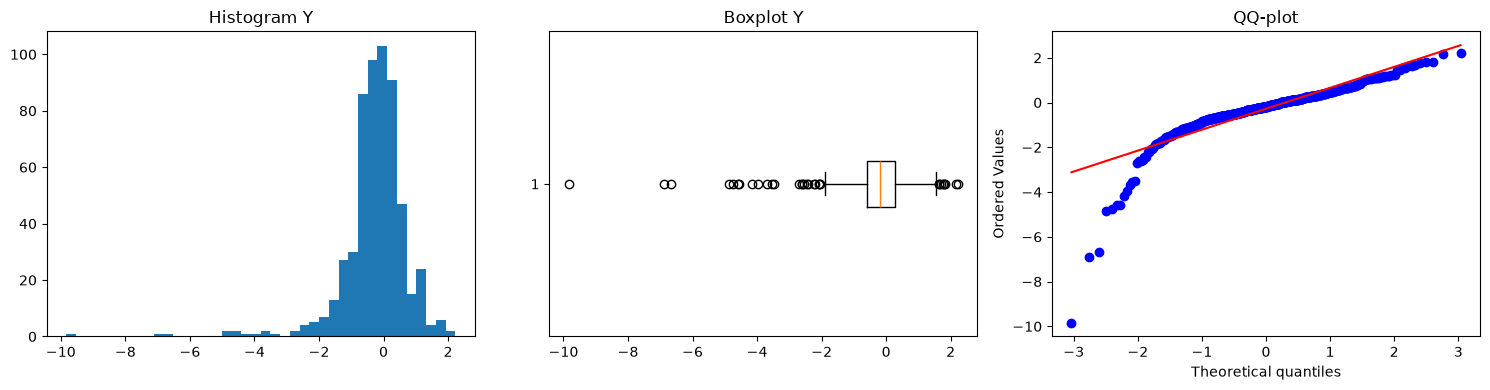

In [4]:
import matplotlib.pyplot as plt
from scipy import stats

m1 = d[(d["role"] == "dev") & (d["mau_chinh"])].copy()
y = m1["Y"]

print("số cặp:", len(m1), "| số franchise:", m1["franchise_id"].nunique())
print(y.describe())
print("độ lệch:", round(y.skew(), 3), "| độ nhọn (dư):", round(y.kurt(), 3))
print(y.quantile([.01, .05, .25, .5, .75, .95, .99]))
print("số cặp có |Y| > 2:", (y.abs() > 2).sum())

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(y, bins=40); ax[0].set_title("Histogram Y")
ax[1].boxplot(y, vert=False); ax[1].set_title("Boxplot Y")
stats.probplot(y, dist="norm", plot=ax[2]); ax[2].set_title("QQ-plot")
plt.tight_layout(); plt.show()

In [5]:
m1["open_prev"] = np.exp(m1["log_open_prev"])
m1["open_curr"] = np.exp(m1["log_open_prev"] + m1["Y"])
m1["pct_change"] = 100 * (np.exp(m1["Y"]) - 1)

ext = m1[m1["Y"].abs() > 2].sort_values("Y")
cols = ["transition_id", "franchise_id", "franchise_position_n",
        "release_year_n", "open_prev", "open_curr", "pct_change", "Y"]
pd.set_option("display.float_format", "{:,.1f}".format)
print(ext[cols].to_string(index=False))

ext[cols].to_csv(r"C:\data_ady_final\final\rq1\outlier_log_Y_dev.csv", index=False)

         transition_id franchise_id  franchise_position_n  release_year_n    open_prev    open_curr  pct_change    Y
FK00008982__FK00110552  TMDBC251970                     2            2013  5,034,180.0        270.0      -100.0 -9.8
FK00010606__FK00035610  TMDBC145784                     2            1993  1,877,000.0      1,926.0       -99.9 -6.9
FK00011351__FK00055341   TMDBC94899                     3            2017 15,269,324.0     19,151.0       -99.9 -6.7
FK00011026__FK00012700   TMDBC12263                     5            2005 18,054,001.0    140,703.0       -99.2 -4.9
FK00003683__FK00001251  TMDBC261382                     2            2006 10,245,190.0     89,097.0       -99.1 -4.7
FK00000862__FK00000863   TMDBC10194                     2            1999 29,140,617.0    300,163.0       -99.0 -4.6
FK00002114__FK00390734 TMDBC1786729                     2            2016 11,408,853.0    119,801.0       -98.9 -4.6
FK00228165__FK00400160  TMDBC275402                     3       

open_curr < 100k: 6
Y               False  True 
open_curr_thap              
False             551     19
True                0      6
                       count      mean    std       min       25%       50%  \
log_open_prev        576.000    16.811  1.113    13.854    16.041    16.915   
gap_years            576.000     4.540  4.489     0.140     1.993     2.995   
franchise_position_n 576.000     3.019  1.735     2.000     2.000     2.000   
release_year_n       576.000 2,006.946 12.582 1,978.000 1,996.750 2,009.000   
release_month_n      576.000     6.790  3.127     1.000     5.000     7.000   

                           75%       max  
log_open_prev           17.661    19.377  
gap_years                5.021    29.109  
franchise_position_n     3.000    12.000  
release_year_n       2,017.000 2,026.000  
release_month_n          9.000    12.000  
độ lệch:
 log_open_prev          -0.290
gap_years               2.600
franchise_position_n    2.460
release_year_n         -0.390
r

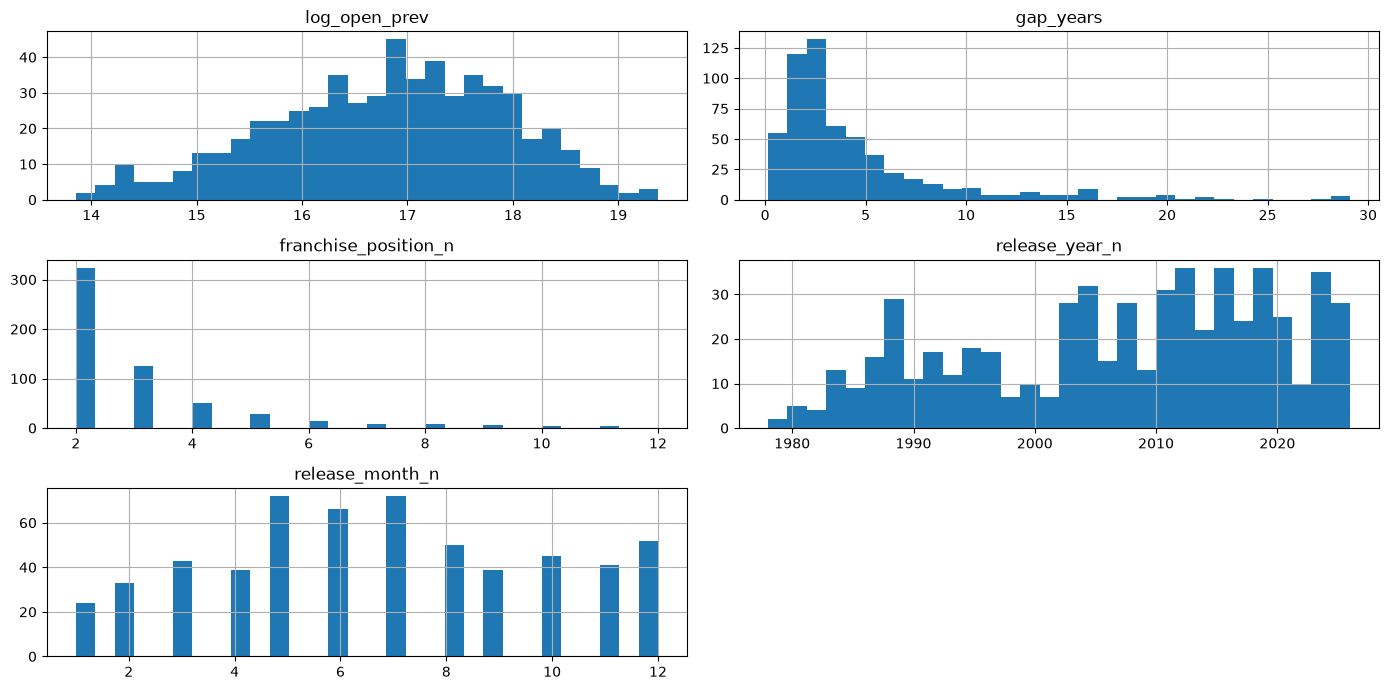

In [6]:
m1["open_curr_thap"] = m1["open_curr"] < 100_000
print("open_curr < 100k:", m1["open_curr_thap"].sum())
print(pd.crosstab(m1["open_curr_thap"], m1["Y"].abs() > 2))

pd.set_option("display.float_format", "{:,.3f}".format)
xs = ["log_open_prev", "gap_years", "franchise_position_n",
      "release_year_n", "release_month_n"]
print(m1[xs].describe().T)
print("độ lệch:\n", m1[xs].skew().round(2))
print("độ nhọn dư:\n", m1[xs].kurt().round(2))
print(m1["franchise_position_n"].value_counts().sort_index())

m1[xs].hist(bins=30, figsize=(14, 7))
plt.tight_layout(); plt.show()

In [7]:
from scipy.stats import spearmanr

rng = np.random.default_rng(42)
pos = m1.groupby("franchise_id").indices      # franchise -> vị trí các dòng
keys = list(pos.keys())

def rho_ci(col, target, B=2000):
    xv, yv = m1[col].to_numpy(), m1[target].to_numpy()
    r0 = spearmanr(xv, yv)[0]
    bs = np.empty(B)
    for b in range(B):
        pick = rng.choice(len(keys), len(keys), replace=True)
        idx = np.concatenate([pos[keys[i]] for i in pick])
        bs[b] = spearmanr(xv[idx], yv[idx])[0]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    p = min(1, 2 * min((bs <= 0).mean(), (bs >= 0).mean()))
    return r0, lo, hi, p

rows = []
for target in ["Y", "abs_Y"]:
    for col in ["log_open_prev", "gap_years", "franchise_position_n", "release_year_n"]:
        r, lo, hi, p = rho_ci(col, target)
        rows.append([target, col, r, lo, hi, p])

res = pd.DataFrame(rows, columns=["target", "bien", "rho", "ci_thap", "ci_cao", "p_thô"])

# hiệu chỉnh Holm
ps = res["p_thô"].to_numpy(); m = len(ps)
order = np.argsort(ps); adj = np.empty(m); run = 0
for rank, i in enumerate(order):
    run = max(run, (m - rank) * ps[i]); adj[i] = min(1, run)
res["p_holm"] = adj

pd.set_option("display.float_format", "{:,.3f}".format)
print(res)
res.to_csv(r"C:\data_ady_final\final\rq1\rq1_spearman_dev.csv", index=False)


  target                  bien    rho  ci_thap  ci_cao  p_thô  p_holm
0      Y         log_open_prev  0.006   -0.092   0.100  0.940   1.000
1      Y             gap_years -0.035   -0.128   0.059  0.487   1.000
2      Y  franchise_position_n  0.033   -0.052   0.112  0.452   1.000
3      Y        release_year_n -0.042   -0.135   0.054  0.392   1.000
4  abs_Y         log_open_prev -0.217   -0.305  -0.132  0.000   0.000
5  abs_Y             gap_years  0.143    0.055   0.222  0.000   0.000
6  abs_Y  franchise_position_n -0.113   -0.186  -0.034  0.006   0.036
7  abs_Y        release_year_n -0.047   -0.145   0.048  0.305   1.000


In [8]:
X = m1[["log_open_prev", "gap_years", "franchise_position_n", "release_year_n"]].copy()
X["gap_years"] = np.log1p(X["gap_years"])     # log vì gap_years lệch phải

print(X.corr(method="spearman").round(2))

R = np.corrcoef(X.to_numpy().T)
vif = pd.Series(np.diag(np.linalg.inv(R)), index=X.columns).round(2)
print(vif)

                      log_open_prev  gap_years  franchise_position_n  \
log_open_prev                 1.000      0.040                 0.140   
gap_years                     0.040      1.000                -0.000   
franchise_position_n          0.140     -0.000                 1.000   
release_year_n                0.560      0.240                 0.090   

                      release_year_n  
log_open_prev                  0.560  
gap_years                      0.240  
franchise_position_n           0.090  
release_year_n                 1.000  
log_open_prev          1.530
gap_years              1.090
franchise_position_n   1.020
release_year_n         1.620
dtype: float64


In [9]:
from scipy.stats import kruskal

m1["nhom_phan"] = np.where(m1["franchise_position_n"] >= 5, "5+",
                           m1["franchise_position_n"].astype(str))
mth = m1["release_month_n"]
m1["mua"] = np.select([mth.between(5, 8), mth.isin([11, 12])],
                      ["he(5-8)", "le(11-12)"], default="khac")

def so_sanh_nhom(g, target, B=2000):
    gv, yv = m1[g].to_numpy(), m1[target].to_numpy()
    levels = sorted(np.unique(gv))
    med = lambda idx: [np.median(yv[idx][gv[idx] == L]) if (gv[idx] == L).any()
                       else np.nan for L in levels]
    obs = med(np.arange(len(m1)))
    bs = np.empty((B, len(levels)))
    for b in range(B):
        pick = rng.choice(len(keys), len(keys), replace=True)
        bs[b] = med(np.concatenate([pos[keys[i]] for i in pick]))
    out = []
    for j, L in enumerate(levels):
        lo, hi = np.nanpercentile(bs[:, j], [2.5, 97.5])
        dif = bs[:, j] - bs[:, 0]
        dlo, dhi = np.nanpercentile(dif, [2.5, 97.5]) if j > 0 else (np.nan, np.nan)
        out.append([L, int((gv == L).sum()), obs[j], lo, hi,
                    obs[j] - obs[0] if j > 0 else np.nan, dlo, dhi])
    t = pd.DataFrame(out, columns=["nhom", "n", "trung_vi", "ci_thap", "ci_cao",
                                   "chenh_vs_nhom1", "chenh_ci_thap", "chenh_ci_cao"])
    p = kruskal(*[yv[gv == L] for L in levels])[1]
    print(f"\n{target} theo {g} | Kruskal-Wallis p (cổ điển, chỉ tham khảo) = {p:.3f}")
    print(t.round(3).to_string(index=False))
    return t

for g in ["nhom_phan", "mua"]:
    for target in ["Y", "abs_Y"]:
        so_sanh_nhom(g, target)


Y theo nhom_phan | Kruskal-Wallis p (cổ điển, chỉ tham khảo) = 0.095
nhom   n  trung_vi  ci_thap  ci_cao  chenh_vs_nhom1  chenh_ci_thap  chenh_ci_cao
   2 324    -0.186   -0.264  -0.078             NaN            NaN           NaN
   3 126    -0.223   -0.403  -0.143          -0.037         -0.255         0.081
   4  51     0.076   -0.101   0.173           0.262          0.076         0.390
  5+  75    -0.210   -0.311  -0.055          -0.024         -0.188         0.166

abs_Y theo nhom_phan | Kruskal-Wallis p (cổ điển, chỉ tham khảo) = 0.040
nhom   n  trung_vi  ci_thap  ci_cao  chenh_vs_nhom1  chenh_ci_thap  chenh_ci_cao
   2 324     0.506    0.435   0.563             NaN            NaN           NaN
   3 126     0.485    0.378   0.546          -0.021         -0.149         0.070
   4  51     0.340    0.241   0.595          -0.166         -0.282         0.098
  5+  75     0.331    0.286   0.458          -0.175         -0.252        -0.039

Y theo mua | Kruskal-Wallis p (cổ điển, chỉ t

In [10]:
m1.to_csv(r"C:\data_ady_final\final\rq1\m1_dev_phan_tich.csv", index=False)

m1["nhom_quy_mo"] = pd.qcut(m1["log_open_prev"], 4,
                            labels=["Q1_nho", "Q2", "Q3", "Q4_lon"]).astype(str)
print(m1.groupby("nhom_quy_mo")["open_prev"].agg(["size", "min", "max"]))

for target in ["Y", "abs_Y"]:
    so_sanh_nhom("nhom_quy_mo", target)

             size            min             max
nhom_quy_mo                                     
Q1_nho        144  1,039,301.000   9,107,816.000
Q2            144  9,312,219.000  22,162,245.000
Q3            144 22,200,000.000  46,630,690.000
Q4_lon        144 47,211,490.000 260,138,569.000

Y theo nhom_quy_mo | Kruskal-Wallis p (cổ điển, chỉ tham khảo) = 0.855
  nhom   n  trung_vi  ci_thap  ci_cao  chenh_vs_nhom1  chenh_ci_thap  chenh_ci_cao
Q1_nho 144    -0.107   -0.354   0.049             NaN            NaN           NaN
    Q2 144    -0.262   -0.329  -0.166          -0.155         -0.353         0.139
    Q3 144    -0.182   -0.292  -0.059          -0.075         -0.301         0.233
Q4_lon 144    -0.131   -0.234  -0.003          -0.024         -0.246         0.268

abs_Y theo nhom_quy_mo | Kruskal-Wallis p (cổ điển, chỉ tham khảo) = 0.000
  nhom   n  trung_vi  ci_thap  ci_cao  chenh_vs_nhom1  chenh_ci_thap  chenh_ci_cao
Q1_nho 144     0.633    0.507   0.762             NaN       

In [11]:
mp = r"C:\data_ady_final\final\rq1\analysis_master_transitions.csv"
ms = pd.read_csv(mp, low_memory=False)
print("Master:", ms.shape)

ms = ms[ms["transition_id"].isin(df["transition_id"])].copy()
print("sau khi lọc 918 cặp:", ms.shape)

want = ["is_director_changed", "studio_changed", "genre_changed", "season_change",
        "budget_log_ratio", "audience_score_prev", "critic_score_prev",
        "open_prev", "open_curr", "comparability_status"]
print({c: (c in ms.columns) for c in want})

kw = ["open", "budget", "score", "changed", "season", "suspect", "flag"]
print([c for c in ms.columns if any(k in c.lower() for k in kw)])

Master: (25943, 228)
sau khi lọc 918 cặp: (918, 228)
{'is_director_changed': True, 'studio_changed': True, 'genre_changed': True, 'season_change': True, 'budget_log_ratio': True, 'audience_score_prev': True, 'critic_score_prev': True, 'open_prev': True, 'open_curr': True, 'comparability_status': True}
['log_open_prev', 'is_director_changed', 'studio_changed', 'budget_log_ratio', 'season_n', 'season_change', 'open_prev', 'open_curr', 'opening_status_prev', 'opening_status_curr', 'opening_inconsistent', 'opening_low_warning_prev', 'opening_low_warning_curr', 'season_prev', 'production_budget_prev', 'production_budget_curr', 'budget_missing_flag_prev', 'budget_missing_flag_curr', 'genre_changed', 'production_company_changed', 'critic_score_prev', 'critic_score_curr', 'delta_critic_score_snapshot', 'audience_score_prev', 'audience_score_curr', 'delta_audience_score_snapshot', 'relationship_type_changed_candidate', 'director_changed_snapshot', 'lead_cast_ids_superset_changed_snapshot', 'glo

In [12]:
ms = ms.set_index("transition_id").loc[df["transition_id"]].reset_index()
if "Y" in ms.columns:
    print("Y khớp với file RQ1:", np.allclose(ms["Y"], df["Y"]))
ms["Y"] = df["Y"].values
ms["abs_Y"] = df["abs_Y"].values
ms["franchise_id"] = df["franchise_id"].values

m2 = ms[(ms["open_prev"] >= 1e6) & (ms["open_curr"] >= 1e6)].copy()
print("M2 nền:", len(m2), "| franchise:", m2["franchise_id"].nunique())

for c in ["opening_inconsistent", "opening_low_warning_prev", "opening_low_warning_curr"]:
    print(c, "| toàn bộ 918:", ms[c].sum(), "| trong M2:", m2[c].sum())

vars2 = ["gap_years", "log_open_prev", "budget_log_ratio", "audience_score_prev",
         "critic_score_prev", "is_director_changed", "studio_changed",
         "genre_changed", "season_change", "season_n"]
print(pd.DataFrame({"thiếu_%": (m2[vars2].isna().mean() * 100).round(1),
                    "kiểu": m2[vars2].dtypes.astype(str),
                    "số_giá_trị": m2[vars2].nunique()}))

Y khớp với file RQ1: True
M2 nền: 689 | franchise: 403
opening_inconsistent | toàn bộ 918: 4 | trong M2: 0
opening_low_warning_prev | toàn bộ 918: 1 | trong M2: 0
opening_low_warning_curr | toàn bộ 918: 5 | trong M2: 0
                     thiếu_%     kiểu  số_giá_trị
gap_years              0.000  float64         512
log_open_prev          0.000  float64         689
budget_log_ratio       5.700  float64         413
audience_score_prev    1.900  float64          78
critic_score_prev      2.200  float64          99
is_director_changed    0.000   object           2
studio_changed         0.000   object           2
genre_changed          0.000   object           2
season_change          0.000     bool           2
season_n               0.000      str           6


In [13]:
def rho_ci_df(dfx, col, target, B=2000):
    s = dfx[[col, target, "franchise_id"]].dropna().reset_index(drop=True)
    pp = s.groupby("franchise_id").indices
    ks = list(pp.keys())
    xv, yv = s[col].to_numpy(float), s[target].to_numpy(float)
    r0 = spearmanr(xv, yv)[0]
    bs = np.empty(B)
    for b in range(B):
        pick = rng.choice(len(ks), len(ks), replace=True)
        idx = np.concatenate([pp[ks[i]] for i in pick])
        bs[b] = spearmanr(xv[idx], yv[idx])[0]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    p = min(1, 2 * min((bs <= 0).mean(), (bs >= 0).mean()))
    return len(s), len(ks), r0, lo, hi, p

cont = ["gap_years", "log_open_prev", "budget_log_ratio",
        "audience_score_prev", "critic_score_prev"]
rows = []
for target in ["Y", "abs_Y"]:
    for col in cont:
        rows.append([target, col, *rho_ci_df(m2, col, target)])
r2 = pd.DataFrame(rows, columns=["target", "bien", "n", "n_franchise",
                                 "rho", "ci_thap", "ci_cao", "p_thô"])

ps = r2["p_thô"].to_numpy(); m = len(ps)
order = np.argsort(ps); adj = np.empty(m); run = 0
for rank, i in enumerate(order):
    run = max(run, (m - rank) * ps[i]); adj[i] = min(1, run)
r2["p_holm"] = adj

pd.set_option("display.float_format", "{:,.3f}".format)
print(r2)
r2.to_csv(r"C:\data_ady_final\final\rq1\rq2_spearman_m2.csv", index=False)

for c in ["is_director_changed", "studio_changed", "genre_changed", "season_n"]:
    print(m2[c].value_counts(dropna=False))

  target                 bien    n  n_franchise    rho  ci_thap  ci_cao  \
0      Y            gap_years  689          403  0.011   -0.069   0.092   
1      Y        log_open_prev  689          403 -0.142   -0.217  -0.064   
2      Y     budget_log_ratio  650          373  0.306    0.230   0.384   
3      Y  audience_score_prev  676          394  0.342    0.269   0.414   
4      Y    critic_score_prev  674          394  0.334    0.260   0.405   
5  abs_Y            gap_years  689          403  0.174    0.101   0.248   
6  abs_Y        log_open_prev  689          403 -0.145   -0.224  -0.058   
7  abs_Y     budget_log_ratio  650          373  0.027   -0.053   0.107   
8  abs_Y  audience_score_prev  676          394 -0.071   -0.161   0.013   
9  abs_Y    critic_score_prev  674          394 -0.084   -0.165  -0.005   

   p_thô  p_holm  
0  0.783   1.000  
1  0.001   0.006  
2  0.000   0.000  
3  0.000   0.000  
4  0.000   0.000  
5  0.000   0.000  
6  0.002   0.010  
7  0.524   1.000  
8  

In [14]:
from scipy.stats import mannwhitneyu

def nhi_phan(dfx, g, target, B=2000):
    s = dfx[[g, target, "Y", "franchise_id"]].dropna().reset_index(drop=True)
    gv = (s[g].astype(str) == "True").to_numpy()
    yv = s[target].to_numpy(float)
    up = (s["Y"].to_numpy(float) > 0)
    pp = s.groupby("franchise_id").indices
    ks = list(pp.keys())

    def stat(idx):
        a, b = yv[idx][gv[idx]], yv[idx][~gv[idx]]
        if len(a) < 2 or len(b) < 2:
            return (np.nan, np.nan, np.nan)
        U = mannwhitneyu(a, b).statistic
        return (np.median(a) - np.median(b),
                2 * U / (len(a) * len(b)) - 1,
                up[idx][gv[idx]].mean() - up[idx][~gv[idx]].mean())

    obs = stat(np.arange(len(s)))
    bs = np.array([stat(np.concatenate([pp[ks[i]] for i in
                   rng.choice(len(ks), len(ks))])) for _ in range(B)])
    ci = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    pb = min(1, 2 * min((bs[:, 1] <= 0).mean(), (bs[:, 1] >= 0).mean()))
    pmw = mannwhitneyu(yv[gv], yv[~gv]).pvalue
    return [g, target, int(gv.sum()), int((~gv).sum()),
            obs[0], ci[0, 0], ci[1, 0],
            obs[1], ci[0, 1], ci[1, 1],
            obs[2], ci[0, 2],

_IncompleteInputError: incomplete input (2909283688.py, line 29)

In [2]:
import pandas as pd, numpy as np
from pathlib import Path

base = Path(r"C:\data_ady_final\final\rq1")

df = pd.read_csv(base / "transitions_model_rq1.csv")
df["abs_Y"] = df["Y"].abs()
rng = np.random.default_rng(42)

ms = pd.read_csv(base / "analysis_master_transitions.csv", low_memory=False)
ms = ms[ms["transition_id"].isin(df["transition_id"])]
ms = ms.set_index("transition_id").loc[df["transition_id"]].reset_index()
ms["Y"] = df["Y"].values
ms["abs_Y"] = df["abs_Y"].values
ms["franchise_id"] = df["franchise_id"].values

m2 = ms[(ms["open_prev"] >= 1e6) & (ms["open_curr"] >= 1e6)].copy()
print("M2:", len(m2), "| franchise:", m2["franchise_id"].nunique())

M2: 689 | franchise: 403


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26432\2752775134.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ms = ms.set_index("transition_id").loc[df["transition_id"]].reset_index()
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_26432\2752775134.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ms["abs_Y"] = df["abs_Y"].values


In [3]:
from scipy.stats import mannwhitneyu, rankdata

def nhi_phan(dfx, g, target, B=2000):
    s = dfx[list(dict.fromkeys([g, target, "Y", "franchise_id"]))].dropna().reset_index(drop=True)
    gv = (s[g].astype(str) == "True").to_numpy()
    yv = s[target].to_numpy(float)
    up = (s["Y"].to_numpy(float) > 0)
    pp = s.groupby("franchise_id").indices
    ks = list(pp.keys())

    def stat(idx):
        a, b = yv[idx][gv[idx]], yv[idx][~gv[idx]]
        if len(a) < 2 or len(b) < 2:
            return np.array([np.nan, np.nan, np.nan])
        r = rankdata(np.concatenate([a, b]))
        U = r[:len(a)].sum() - len(a) * (len(a) + 1) / 2
        return np.array([float(np.median(a) - np.median(b)),
                         float(2 * U / (len(a) * len(b)) - 1),
                         float(up[idx][gv[idx]].mean() - up[idx][~gv[idx]].mean())])

    obs = stat(np.arange(len(s)))
    bs = np.empty((B, 3))
    for k in range(B):
        pick = rng.choice(len(ks), len(ks), replace=True)
        bs[k] = stat(np.concatenate([pp[ks[i]] for i in pick]))
    ci = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    pb = min(1, 2 * min((bs[:, 1] <= 0).mean(), (bs[:, 1] >= 0).mean()))
    pmw = float(mannwhitneyu(yv[gv], yv[~gv]).pvalue)
    return [g, target, int(gv.sum()), int((~gv).sum()),
            obs[0], ci[0, 0], ci[1, 0],
            obs[1], ci[0, 1], ci[1, 1],
            obs[2], ci[0, 2], ci[1, 2], pb, pmw]

cols = ["bien", "target", "n_doi", "n_khong", "chenh_tv", "tv_lo", "tv_hi",
        "cliff", "cl_lo", "cl_hi", "chenh_ty_le_tang", "tl_lo", "tl_hi",
        "p_boot", "p_MW_codien"]
rows = [nhi_phan(m2, g, t) for g in ["is_director_changed", "studio_changed",
        "genre_changed", "season_change"] for t in ["Y", "abs_Y"]]
r3 = pd.DataFrame(rows, columns=cols)

ps = r3["p_boot"].to_numpy(); m = len(ps)
order = np.argsort(ps); adj = np.empty(m); run = 0
for rank, i in enumerate(order):
    run = max(run, (m - rank) * ps[i]); adj[i] = min(1, run)
r3["p_holm"] = adj

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 250)
print(r3.to_string(index=False))
r3.to_csv(r"C:\data_ady_final\final\rq1\rq2_nhom_nhi_phan_m2.csv", index=False)

               bien target  n_doi  n_khong  chenh_tv  tv_lo  tv_hi  cliff  cl_lo  cl_hi  chenh_ty_le_tang  tl_lo  tl_hi  p_boot  p_MW_codien  p_holm
is_director_changed      Y    420      269    -0.115 -0.229 -0.001 -0.094 -0.181 -0.010            -0.041 -0.114  0.030   0.028        0.038   0.140
is_director_changed  abs_Y    420      269     0.085 -0.004  0.184  0.124  0.035  0.221            -0.041 -0.113  0.032   0.010        0.006   0.070
     studio_changed      Y    500      189    -0.089 -0.247  0.057 -0.085 -0.192  0.019            -0.053 -0.144  0.041   0.111        0.084   0.333
     studio_changed  abs_Y    500      189     0.092 -0.029  0.171  0.064 -0.037  0.174            -0.053 -0.144  0.044   0.221        0.194   0.424
      genre_changed      Y    320      369    -0.103 -0.245  0.039 -0.120 -0.209 -0.031            -0.043 -0.118  0.036   0.011        0.006   0.070
      genre_changed  abs_Y    320      369     0.080  0.006  0.178  0.088 -0.005  0.175            -0.043 

In [4]:
from scipy.stats import spearmanr, kruskal, rankdata

def rho_ci_df(dfx, col, target, B=2000):
    s = dfx[list(dict.fromkeys([col, target, "franchise_id"]))].dropna().reset_index(drop=True)
    pp = s.groupby("franchise_id").indices
    ks = list(pp.keys())
    xv, yv = s[col].to_numpy(float), s[target].to_numpy(float)
    r0 = spearmanr(xv, yv)[0]
    bs = np.empty(B)
    for b in range(B):
        pick = rng.choice(len(ks), len(ks), replace=True)
        idx = np.concatenate([pp[ks[i]] for i in pick])
        bs[b] = spearmanr(xv[idx], yv[idx])[0]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    p = min(1, 2 * min((bs <= 0).mean(), (bs >= 0).mean()))
    return [len(s), len(ks), r0, lo, hi, p]

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 250)

# ---- 1) Độ nhạy RQ1: bỏ 6 cặp opening phim sau < 100k
m1 = pd.read_csv(base / "m1_dev_phan_tich.csv")
m1s = m1[~m1["open_curr_thap"]]
rows = [[t, c, *rho_ci_df(m1s, c, t)] for t in ["Y", "abs_Y"]
        for c in ["log_open_prev", "gap_years", "franchise_position_n", "release_year_n"]]
print("\n=== RQ1 độ nhạy (bỏ 6 cặp opening phim sau < 100k) ===")
print(pd.DataFrame(rows, columns=["target", "bien", "n", "n_fr", "rho", "lo", "hi", "p"]))

# ---- 2) RQ2.6: độ nhạy theo ngưỡng và missingness (Y với 4 biến chính)
variants = {
    "nen>=1M (M2)": m2,
    ">=500k": ms[(ms["open_prev"] >= 5e5) & (ms["open_curr"] >= 5e5)],
    ">=2M": ms[(ms["open_prev"] >= 2e6) & (ms["open_curr"] >= 2e6)],
    "M2 đủ score+ngân sách": m2.dropna(subset=["budget_log_ratio", "audience_score_prev", "critic_score_prev"]),
}
rows = [[v, c, *rho_ci_df(dfx, c, "Y")] for v, dfx in variants.items()
        for c in ["log_open_prev", "budget_log_ratio", "audience_score_prev", "critic_score_prev"]]
print("\n=== RQ2.6 độ nhạy ===")
print(pd.DataFrame(rows, columns=["mau", "bien", "n", "n_fr", "rho", "lo", "hi", "p"]))

# ---- 3) So sánh nhóm nhiều mức (6 mùa) bằng bootstrap theo franchise
def so_sanh_nhom2(dfx, g, target, B=2000):
    s = dfx[list(dict.fromkeys([g, target, "franchise_id"]))].dropna().reset_index(drop=True)
    gv = s[g].astype(str).to_numpy()
    yv = s[target].to_numpy(float)
    levels = sorted(np.unique(gv))
    pp = s.groupby("franchise_id").indices
    ks = list(pp.keys())
    def med(idx):
        out = []
        for L in levels:
            v = yv[idx][gv[idx] == L]
            out.append(np.median(v) if len(v) else np.nan)
        return np.array(out)
    obs = med(np.arange(len(s)))
    bs = np.empty((B, len(levels)))
    for k in range(B):
        pick = rng.choice(len(ks), len(ks), replace=True)
        bs[k] = med(np.concatenate([pp[ks[i]] for i in pick]))
    rows = []
    for j, L in enumerate(levels):
        lo, hi = np.nanpercentile(bs[:, j], [2.5, 97.5])
        if j == 0:
            d = dlo = dhi = np.nan
        else:
            d = obs[j] - obs[0]
            dlo, dhi = np.nanpercentile(bs[:, j] - bs[:, 0], [2.5, 97.5])
        rows.append([L, int((gv == L).sum()), obs[j], lo, hi, d, dlo, dhi])
    t = pd.DataFrame(rows, columns=["nhom", "n", "trung_vi", "lo", "hi",
                                    "chenh_vs_nhom1", "chenh_lo", "chenh_hi"])
    p = kruskal(*[yv[gv == L] for L in levels])[1]
    print(f"\n{target} theo {g} | KW p (cổ điển) = {p:.3f} | nhóm gốc = {levels[0]}")
    print(t.round(3).to_string(index=False))
    return t

print("\n=== RQ2.3: 6 mùa (M2) ===")
for t in ["Y", "abs_Y"]:
    so_sanh_nhom2(m2, "season_n", t)


=== RQ1 độ nhạy (bỏ 6 cặp opening phim sau < 100k) ===
  target                  bien    n  n_fr    rho     lo     hi     p
0      Y         log_open_prev  570   338 -0.016 -0.108  0.078 0.708
1      Y             gap_years  570   338 -0.034 -0.134  0.056 0.437
2      Y  franchise_position_n  570   338  0.027 -0.057  0.102 0.602
3      Y        release_year_n  570   338 -0.050 -0.143  0.039 0.276
4  abs_Y         log_open_prev  570   338 -0.200 -0.288 -0.107 0.000
5  abs_Y             gap_years  570   338  0.144  0.055  0.225 0.001
6  abs_Y  franchise_position_n  570   338 -0.109 -0.180 -0.030 0.009
7  abs_Y        release_year_n  570   338 -0.041 -0.138  0.053 0.383

=== RQ2.6 độ nhạy ===
                      mau                 bien    n  n_fr    rho     lo     hi     p
0            nen>=1M (M2)        log_open_prev  689   403 -0.142 -0.223 -0.065 0.000
1            nen>=1M (M2)     budget_log_ratio  650   373  0.306  0.230  0.378 0.000
2            nen>=1M (M2)  audience_score_pre

In [5]:
import statsmodels.formula.api as smf

cont = ["log_open_prev", "gap_years", "budget_log_ratio",
        "audience_score_prev", "critic_score_prev"]
binv = ["is_director_changed", "studio_changed", "genre_changed", "season_change"]

for target in ["Y", "abs_Y"]:
    mm = m2[[target, "franchise_id"] + cont + binv].dropna().copy()
    mm["gap_years"] = np.log1p(mm["gap_years"])
    for c in cont:
        mm[c] = (mm[c] - mm[c].mean()) / mm[c].std()
    for c in binv:
        mm[c] = (mm[c].astype(str) == "True").astype(int)
    fit = smf.ols(f"{target} ~ " + " + ".join(cont + binv), data=mm).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(mm["franchise_id"])[0]})
    tb = pd.DataFrame({"he_so": fit.params, "ci_thap": fit.conf_int()[0],
                       "ci_cao": fit.conf_int()[1], "p": fit.pvalues})
    print(f"\n=== OLS cluster-robust: {target} | n = {len(mm)} | "
          f"franchise = {mm['franchise_id'].nunique()} | R2 = {fit.rsquared:.3f} ===")
    print(tb.round(3))

R = np.corrcoef(mm[cont].to_numpy().T)
print("\nVIF:", dict(zip(cont, np.diag(np.linalg.inv(R)).round(2))))


=== OLS cluster-robust: Y | n = 637 | franchise = 365 | R2 = 0.287 ===
                     he_so  ci_thap  ci_cao     p
Intercept            0.035   -0.079   0.150 0.543
log_open_prev       -0.167   -0.220  -0.114 0.000
gap_years            0.044   -0.014   0.103 0.135
budget_log_ratio     0.189    0.136   0.243 0.000
audience_score_prev  0.168    0.104   0.232 0.000
critic_score_prev    0.056   -0.010   0.123 0.098
is_director_changed -0.042   -0.131   0.048 0.363
studio_changed      -0.086   -0.190   0.018 0.105
genre_changed       -0.142   -0.243  -0.042 0.005
season_change        0.024   -0.070   0.118 0.619

=== OLS cluster-robust: abs_Y | n = 637 | franchise = 365 | R2 = 0.114 ===
                     he_so  ci_thap  ci_cao     p
Intercept            0.467    0.382   0.553 0.000
log_open_prev       -0.058   -0.102  -0.014 0.010
gap_years            0.109    0.069   0.148 0.000
budget_log_ratio     0.025   -0.047   0.097 0.500
audience_score_prev  0.010   -0.040   0.060 0.698
cr

In [6]:
flags = ms[["transition_id", "opening_inconsistent",
            "opening_low_warning_prev", "opening_low_warning_curr"]]
a0 = df.merge(flags, on="transition_id")
cờ = (a0["opening_inconsistent"].astype(bool) | a0["opening_low_warning_prev"].astype(bool)
      | a0["opening_low_warning_curr"].astype(bool))
a0s = a0[~cờ].copy()
print("A0:", len(a0), "| bỏ cặp bị cờ:", len(a0s), "| số cặp bị cờ:", int(cờ.sum()))

def them_nhom(x):
    x = x.copy()
    x["nhom_phan"] = np.where(x["franchise_position_n"] >= 5, "5+",
                              x["franchise_position_n"].astype(str))
    x["giai_doan"] = pd.cut(x["release_year_n"], [0, 1989, 1999, 2009, 2019, 3000],
                            labels=["a_<1990", "b_1990s", "c_2000s", "d_2010s", "e_2020+"]).astype(str)
    return x

def icc_hang(dfx, B=1000):
    s = dfx[["franchise_id", "Y"]].copy()
    s["r"] = rankdata(s["Y"])
    s = s[s.groupby("franchise_id")["r"].transform("size") >= 2]
    gs = [g["r"].to_numpy() for _, g in s.groupby("franchise_id")]
    def icc(groups):
        k = len(groups); n = np.array([len(g) for g in groups]); N = n.sum()
        grand = np.concatenate(groups).mean()
        msb = sum(ni * (g.mean() - grand) ** 2 for ni, g in zip(n, groups)) / (k - 1)
        msw = sum(((g - g.mean()) ** 2).sum() for g in groups) / (N - k)
        n0 = (N - (n ** 2).sum() / N) / (k - 1)
        return (msb - msw) / (msb + (n0 - 1) * msw)
    obs = icc(gs)
    bs = [icc([gs[i] for i in rng.choice(len(gs), len(gs))]) for _ in range(B)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    print(f"ICC (trên hạng của Y) = {obs:.3f}, CI {lo:.3f} đến {hi:.3f} "
          f"| {len(gs)} franchise có từ 2 cặp, {len(s)} cặp")

for ten, x in [("A0 (918)", a0), ("A0 bỏ cặp bị cờ", a0s)]:
    x = them_nhom(x)
    print(f"\n################ {ten} ################")
    rows = [[t, *rho_ci_df(x, "franchise_position_n", t)] for t in ["Y", "abs_Y"]]
    rows += [[t + " ~ release_year_n", *rho_ci_df(x, "release_year_n", t)] for t in ["Y", "abs_Y"]]
    print(pd.DataFrame(rows, columns=["spearman_voi", "n", "n_fr", "rho", "lo", "hi", "p"]))
    for g in ["nhom_phan", "giai_doan"]:
        for t in ["Y", "abs_Y"]:
            so_sanh_nhom2(x, g, t)
    icc_hang(x)

a0 = them_nhom(a0)
a0["chuoi_dai"] = a0.groupby("franchise_id")["franchise_id"].transform("size") >= 3
print("\n=== RQ3.6: franchise có >= 3 cặp so với ít hơn ===")
print(pd.DataFrame([nhi_phan(a0, "chuoi_dai", t) for t in ["Y", "abs_Y"]], columns=cols).round(3).to_string(index=False))

A0: 918 | bỏ cặp bị cờ: 908 | số cặp bị cờ: 10

################ A0 (918) ################
             spearman_voi    n  n_fr    rho     lo     hi     p
0                       Y  918   562  0.023 -0.042  0.081 0.460
1                   abs_Y  918   562 -0.139 -0.203 -0.072 0.000
2      Y ~ release_year_n  918   562 -0.061 -0.128  0.005 0.066
3  abs_Y ~ release_year_n  918   562  0.051 -0.028  0.131 0.242

Y theo nhom_phan | KW p (cổ điển) = 0.444 | nhóm gốc = 2
nhom   n  trung_vi     lo     hi  chenh_vs_nhom1  chenh_lo  chenh_hi
   2 515    -0.147 -0.252 -0.064             NaN       NaN       NaN
   3 207    -0.190 -0.281 -0.080          -0.042    -0.160     0.108
   4  86     0.017 -0.169  0.110           0.165    -0.018     0.305
  5+ 110    -0.156 -0.299  0.011          -0.009    -0.198     0.192

abs_Y theo nhom_phan | KW p (cổ điển) = 0.000 | nhóm gốc = 2
nhom   n  trung_vi    lo    hi  chenh_vs_nhom1  chenh_lo  chenh_hi
   2 515     0.605 0.546 0.658             NaN       NaN 

In [7]:
from scipy.stats import spearmanr, kruskal, rankdata

def rho_ci_df(dfx, col, target, B=2000):
    s = dfx[list(dict.fromkeys([col, target, "franchise_id"]))].dropna().reset_index(drop=True)
    pp = s.groupby("franchise_id").indices
    ks = list(pp.keys())
    xv, yv = s[col].to_numpy(float), s[target].to_numpy(float)
    r0 = spearmanr(xv, yv)[0]
    bs = np.empty(B)
    for b in range(B):
        pick = rng.choice(len(ks), len(ks), replace=True)
        idx = np.concatenate([pp[ks[i]] for i in pick])
        bs[b] = spearmanr(xv[idx], yv[idx])[0]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    p = min(1, 2 * min((bs <= 0).mean(), (bs >= 0).mean()))
    return [len(s), len(ks), r0, lo, hi, p]

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 250)

# ---- 1) Độ nhạy RQ1: bỏ 6 cặp opening phim sau < 100k
m1 = pd.read_csv(base / "m1_dev_phan_tich.csv")
m1s = m1[~m1["open_curr_thap"]]
rows = [[t, c, *rho_ci_df(m1s, c, t)] for t in ["Y", "abs_Y"]
        for c in ["log_open_prev", "gap_years", "franchise_position_n", "release_year_n"]]
print("\n=== RQ1 độ nhạy (bỏ 6 cặp opening phim sau < 100k) ===")
print(pd.DataFrame(rows, columns=["target", "bien", "n", "n_fr", "rho", "lo", "hi", "p"]))

# ---- 2) RQ2.6: độ nhạy theo ngưỡng và missingness (Y với 4 biến chính)
variants = {
    "nen>=1M (M2)": m2,
    ">=500k": ms[(ms["open_prev"] >= 5e5) & (ms["open_curr"] >= 5e5)],
    ">=2M": ms[(ms["open_prev"] >= 2e6) & (ms["open_curr"] >= 2e6)],
    "M2 đủ score+ngân sách": m2.dropna(subset=["budget_log_ratio", "audience_score_prev", "critic_score_prev"]),
}
rows = [[v, c, *rho_ci_df(dfx, c, "Y")] for v, dfx in variants.items()
        for c in ["log_open_prev", "budget_log_ratio", "audience_score_prev", "critic_score_prev"]]
print("\n=== RQ2.6 độ nhạy ===")
print(pd.DataFrame(rows, columns=["mau", "bien", "n", "n_fr", "rho", "lo", "hi", "p"]))

# ---- 3) So sánh nhóm nhiều mức (6 mùa) bằng bootstrap theo franchise
def so_sanh_nhom2(dfx, g, target, B=2000):
    s = dfx[list(dict.fromkeys([g, target, "franchise_id"]))].dropna().reset_index(drop=True)
    gv = s[g].astype(str).to_numpy()
    yv = s[target].to_numpy(float)
    levels = sorted(np.unique(gv))
    pp = s.groupby("franchise_id").indices
    ks = list(pp.keys())
    def med(idx):
        out = []
        for L in levels:
            v = yv[idx][gv[idx] == L]
            out.append(np.median(v) if len(v) else np.nan)
        return np.array(out)
    obs = med(np.arange(len(s)))
    bs = np.empty((B, len(levels)))
    for k in range(B):
        pick = rng.choice(len(ks), len(ks), replace=True)
        bs[k] = med(np.concatenate([pp[ks[i]] for i in pick]))
    rows = []
    for j, L in enumerate(levels):
        lo, hi = np.nanpercentile(bs[:, j], [2.5, 97.5])
        if j == 0:
            d = dlo = dhi = np.nan
        else:
            d = obs[j] - obs[0]
            dlo, dhi = np.nanpercentile(bs[:, j] - bs[:, 0], [2.5, 97.5])
        rows.append([L, int((gv == L).sum()), obs[j], lo, hi, d, dlo, dhi])
    t = pd.DataFrame(rows, columns=["nhom", "n", "trung_vi", "lo", "hi",
                                    "chenh_vs_nhom1", "chenh_lo", "chenh_hi"])
    p = kruskal(*[yv[gv == L] for L in levels])[1]
    print(f"\n{target} theo {g} | KW p (cổ điển) = {p:.3f} | nhóm gốc = {levels[0]}")
    print(t.round(3).to_string(index=False))
    return t

print("\n=== RQ2.3: 6 mùa (M2) ===")
for t in ["Y", "abs_Y"]:
    so_sanh_nhom2(m2, "season_n", t)


=== RQ1 độ nhạy (bỏ 6 cặp opening phim sau < 100k) ===
  target                  bien    n  n_fr    rho     lo     hi     p
0      Y         log_open_prev  570   338 -0.016 -0.109  0.080 0.731
1      Y             gap_years  570   338 -0.034 -0.130  0.060 0.460
2      Y  franchise_position_n  570   338  0.027 -0.061  0.105 0.558
3      Y        release_year_n  570   338 -0.050 -0.144  0.043 0.321
4  abs_Y         log_open_prev  570   338 -0.200 -0.288 -0.111 0.000
5  abs_Y             gap_years  570   338  0.144  0.063  0.227 0.001
6  abs_Y  franchise_position_n  570   338 -0.109 -0.176 -0.029 0.006
7  abs_Y        release_year_n  570   338 -0.041 -0.137  0.059 0.409

=== RQ2.6 độ nhạy ===
                      mau                 bien    n  n_fr    rho     lo     hi     p
0            nen>=1M (M2)        log_open_prev  689   403 -0.142 -0.223 -0.064 0.000
1            nen>=1M (M2)     budget_log_ratio  650   373  0.306  0.230  0.381 0.000
2            nen>=1M (M2)  audience_score_pre

In [9]:
ids = pd.read_csv(r"C:\data_ady_final\ids_A1b.csv")["transition_id"]
a1b = df[df["transition_id"].isin(ids)].copy()
print("A1b:", len(a1b), "| franchise:", a1b["franchise_id"].nunique())   # kỳ vọng 910 và 557

# 8 cặp bị loại khỏi A1b, đối chiếu với cờ Master và split RQ1
excl = ms[~ms["transition_id"].isin(ids)]
print("\n8 cặp bị loại:")
print(excl[["transition_id", "franchise_id", "open_prev", "open_curr", "Y",
            "opening_inconsistent", "opening_low_warning_prev",
            "opening_low_warning_curr"]].to_string(index=False))

sp = pd.read_csv(base / "rq1_split_v2.csv")
print("\nVị trí của 8 cặp trong split RQ1:")
print(sp[sp["transition_id"].isin(excl["transition_id"])][["transition_id", "role", "mau_chinh"]])

co_master = ms[ms["opening_inconsistent"].astype(bool)
               | ms["opening_low_warning_prev"].astype(bool)
               | ms["opening_low_warning_curr"].astype(bool)]
print("\nCặp cờ Master:", len(co_master), "| trong đó nằm trong A1b:",
      co_master["transition_id"].isin(ids).sum())

# ---- RQ3 chạy lại trên đúng mẫu A1b
x = them_nhom(a1b)
rows = [[t, *rho_ci_df(x, "franchise_position_n", t)] for t in ["Y", "abs_Y"]]
print("\nSpearman với thứ tự phần:")
print(pd.DataFrame(rows, columns=["target", "n", "n_fr", "rho", "lo", "hi", "p"]))

for g in ["nhom_phan", "giai_doan"]:
    for t in ["Y", "abs_Y"]:
        so_sanh_nhom2(x, g, t)
icc_hang(x)

x["chuoi_dai"] = x.groupby("franchise_id")["franchise_id"].transform("size") >= 3
print("\nRQ3.6 franchise >= 3 cặp so với ít hơn:")
print(pd.DataFrame([nhi_phan(x, "chuoi_dai", t) for t in ["Y", "abs_Y"]],
                   columns=cols).round(3).to_string(index=False))

A1b: 910 | franchise: 557

8 cặp bị loại:
         transition_id franchise_id   open_prev   open_curr      Y  opening_inconsistent  opening_low_warning_prev  opening_low_warning_curr
FK00042818__FK00043146  TMDBC156152   7,720.000   7,720.000  0.000                 False                     False                     False
FK00043146__FK00043873  TMDBC156152   7,720.000   7,720.000  0.000                 False                     False                     False
FK00000897__FK00000896  TMDBC158391  16,064.000  16,064.000  0.000                 False                     False                     False
FK00000256__FK00000255  TMDBC185682  11,206.000  11,206.000  0.000                  True                     False                     False
FK00000255__FK00000258  TMDBC185682  11,206.000  11,206.000  0.000                  True                     False                     False
FK00000258__FK00000259  TMDBC185682  11,206.000  11,206.000  0.000                  True                     Fal